# Chicago traffic assignment benchmark

Compare AequilibraE 2.0 and Quetzal on the Chicago regional model. Run both solvers in the same Python 3.12 environment with the AequilibraE 2.0 wheel built for Python 3.12.

In [ ]:
import os
from dataclasses import replace
from pathlib import Path

os.environ["AEQ_SHOW_PROGRESS"] = "FALSE"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from aequilibrae import Project, __version__
from aequilibrae.traffic import TrafficAssignment, TrafficClass
from aequilibrae.traffic.vdf import bpr
from IPython.display import display
from quetzal.model import stepmodel
from scipy.stats import linregress

model_path = Path("model")
if not (model_path / "project_database.sqlite").is_file():
    model_path = Path("benchmarks/chicago") / model_path

tolerance = 1e-5
max_iterations = 1000
num_threads = 16
method = "bfw"
time_field = "free_flow_time"
use_benchmark_turn_penalty = False

## Load the Chicago network and demand

The network and selected OMX matrix remain available after the project closes. Quetzal uses the same directed links and the zone IDs from the OMX index.

In [2]:
with Project(model_path) as project:
    network = project.road.build_network(
        fields=[time_field, "capacity", "b", "power", "distance"], modes=["c"]
    )
    demand = project.matrices.get_matrix("demand.omx", subset=["matrix"])

print(f"AequilibraE {__version__}")
print(
    f"{len(network.links):,} links, {len(demand.index):,} zones, {demand['matrix'].sum():,.2f} trips"
)

AequilibraE 2.0.0b1
39,018 links, 1,790 zones, 1,360,427.88 trips


## AequilibraE assignment

AequilibraE builds the car graph from the traffic class settings. Set `use_benchmark_turn_penalty = True` to enable the original benchmark's zero-cost placeholder turn and run both solvers with turn-aware routing.

In [3]:
assignment_network = network
if use_benchmark_turn_penalty:
    turns = pd.DataFrame(
        [(1, 10293, 1, 0.0)], columns=["from_node", "via_node", "to_node", "penalty"]
    )
    assignment_network = replace(network, turn_restrictions=turns)

car = TrafficClass(
    name="car",
    mode="c",
    cost=time_field,
    demand=demand,
    graph_options={
        "allow_uturns": False,
        "block_centroid_flows": True,
    },
)
assignment = TrafficAssignment(
    network=assignment_network,
    classes=[car],
    time_field=time_field,
    capacity_field="capacity",
    vdf=bpr,
    name_mapping={"alpha": "b", "beta": "power"},
    algorithm=method,
)

aeq_flows = assignment.execute(
    max_iterations=max_iterations,
    rgap=tolerance,
    cores=num_threads,
    threading_threshold=10000,
    elementwise_cores=min(6, num_threads),
)
aeq_report = assignment.report()

display(aeq_report[["iteration", "rgap", "time", "alpha"]].tail())
aeq_flows[["matrix_ab", "matrix_ba", "PCE_tot", "VOC_max"]].head()

,iteration,rgap,time,alpha
728,729,0.000012,110.820893,0.000947
729,730,0.000010,110.962965,0.001104
730,731,0.000010,111.152397,0.000838
731,732,0.000011,111.293772,0.001050
732,733,0.000010,111.440595,NaN


,matrix_ab,matrix_ba,PCE_tot,VOC_max
link_id,,,,
1,1380.42,0.0,1380.42,0.013804
2,1271.61,0.0,1271.61,0.012716
3,154.18,0.0,154.18,0.001542
4,1223.55,0.0,1223.55,0.012235
5,353.92,0.0,353.92,0.003539


## Quetzal assignment

Use the same directed network and OMX demand. Quetzal takes the relative gap as a percentage.

In [4]:
mapping = network.mapping
tails = mapping.node_ids[mapping.link_tails]
heads = mapping.node_ids[mapping.link_heads]
quetzal_links = pd.DataFrame(
    {
        "link_id": network.link_ids,
        "link_direction": network.directions,
        "a": tails,
        "b": heads,
        "time": network.field_values(time_field),
        "capacity": network.field_values("capacity"),
        "alpha": network.field_values("b"),
        "beta": network.field_values("power"),
        "length": network.field_values("distance"),
        # Quetzal expects the literal "eggress" for links entering a zone.
        "connector": np.select(
            [np.isin(tails, network.centroids), np.isin(heads, network.centroids)],
            ["access", "eggress"],
            default="",
        ),
    }
)
matrix = demand["matrix"]
origins, destinations = np.nonzero(matrix)
volumes = pd.DataFrame(
    {
        "origin": demand.index[origins],
        "destination": demand.index[destinations],
        "car": matrix[origins, destinations],
    }
)

quetzal_links = quetzal_links.set_index("link_id", drop=False)
quetzal_links.index.name = "index"
quetzal_links["segments"] = [{"car"} for _ in range(len(quetzal_links))]
quetzal_links["vdf"] = "bpr"

sm = stepmodel.StepModel()
sm.volumes = volumes
is_connector = quetzal_links["connector"].ne("")
sm.road_links = quetzal_links.loc[~is_connector].drop(columns="connector")
sm.zone_to_road = quetzal_links.loc[is_connector].rename(
    columns={"connector": "direction"}
)

turn_options = (
    {"turn_penalties": {1: [1]}, "turn_penalty": 0}
    if use_benchmark_turn_penalty
    else {}
)
sm.step_road_pathfinder(
    method=method,
    maxiters=max_iterations,
    tolerance=tolerance * 100.0,
    segments=["car"],
    vdf={"bpr": "time * (1 + alpha * (flow / capacity) ** beta)"},
    num_cores=num_threads,
    return_car_los=False,
    log=True,
    **turn_options,
)

it  |  Phi    |  Rel Gap (%)
 1  |  1.000  |  87.94322911 
 2  |  0.199  |  70.94480605 
 3  |  0.189  |  47.45011338 
 4  |  0.145  |  30.76044348 
 5  |  0.154  |  18.81619044 
 6  |  0.174  |  12.07856895 
 7  |  0.175  |  8.25633946 
 8  |  0.195  |  6.61660595 
 9  |  0.267  |  6.10665378 
10  |  0.331  |  4.79325807 
11  |  0.314  |  3.98973642 
12  |  0.299  |  3.13833726 
13  |  0.286  |  2.15342956 
14  |  0.164  |  2.20879018 
15  |  0.244  |  2.20397468 
16  |  0.256  |  2.12393744 
17  |  0.248  |  1.65572101 
18  |  0.241  |  1.71030172 
19  |  0.234  |  1.31418717 
20  |  0.228  |  1.01963260 
21  |  0.190  |  0.96504916 
22  |  0.163  |  1.01503747 
23  |  0.211  |  0.88851366 
24  |  0.207  |  0.69746078 
25  |  0.079  |  0.63482181 
26  |  0.198  |  0.61369726 
27  |  0.195  |  0.54938585 
28  |  0.191  |  0.51338288 
29  |  0.187  |  0.40262925 
30  |  0.184  |  0.39532312 
31  |  0.181  |  0.34911207 
32  |  0.178  |  0.27058794 
33  |  0.175  |  0.30991515 
34  |  0

## Plots

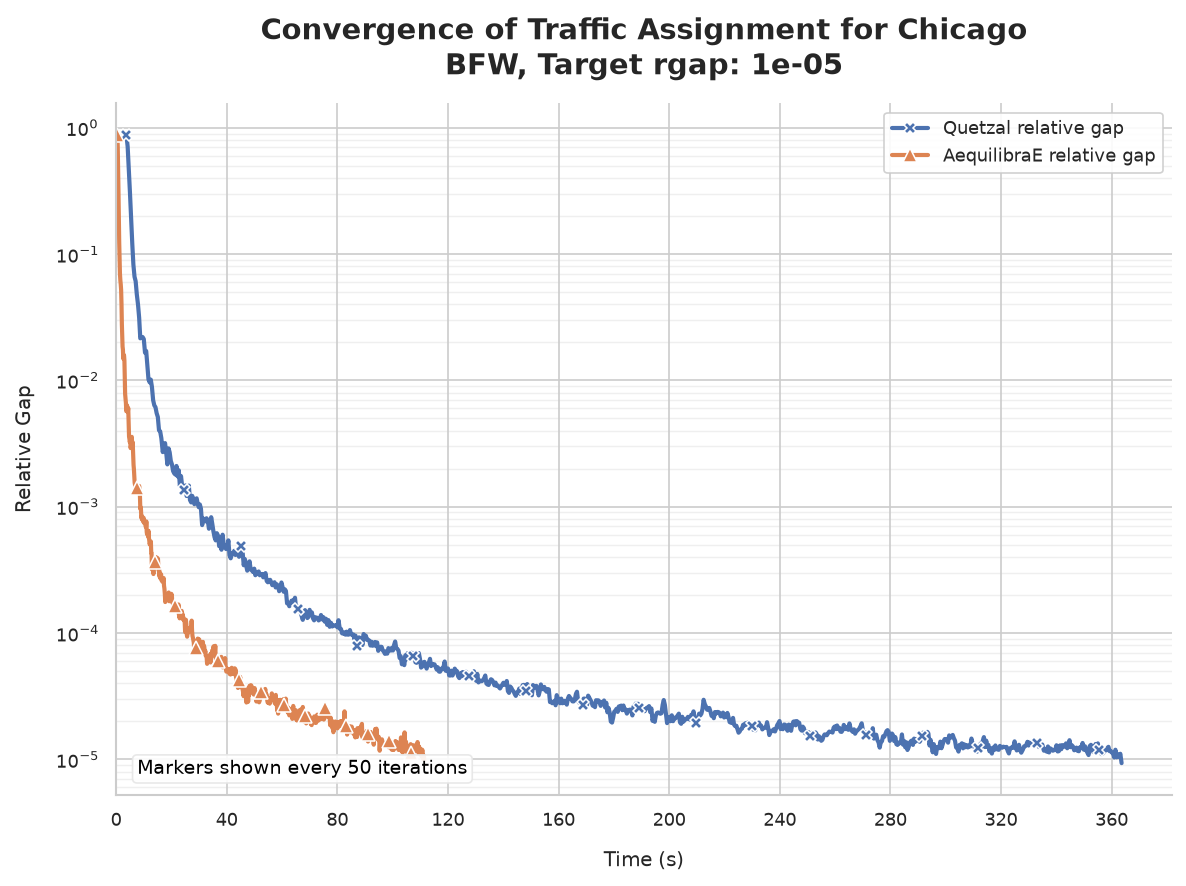

In [5]:
def plot_convergence(
    sm, aeq_report, name, max_iterations, method, tolerance, plot_time=True
):
    sns.set_theme(style="whitegrid", context="paper")

    fig, ax = plt.subplots(figsize=(8, 6), dpi=150)
    palette = sns.color_palette()
    marker_interval = max(1, max_iterations // 20)

    if plot_time:
        x_label = "Time (s)"
        x_sm = sm.times
        x_aeq = aeq_report["time"]
    else:
        x_label = "Iterations"
        x_sm = range(len(sm.relgap))
        x_aeq = aeq_report.index

    sns.lineplot(
        x=x_sm,
        y=[x / 100.0 for x in sm.relgap],
        label="Quetzal relative gap",
        ax=ax,
        marker="X",
        markevery=marker_interval,
        markersize=6,
        color=palette[0],
        linewidth=2,
    )
    sns.lineplot(
        x=x_aeq,
        y=aeq_report["rgap"],
        label="AequilibraE relative gap",
        ax=ax,
        marker="^",
        markevery=marker_interval,
        markersize=7,
        color=palette[1],
        linewidth=2,
    )

    ax.set_xlim(left=0)
    ax.set_yscale("log")
    ax.grid(True, which="minor", axis="y", linewidth=0.7, alpha=0.3)

    ax.set_xlabel(x_label, labelpad=10)
    ax.set_ylabel("Relative Gap", labelpad=10)
    ax.set_title(
        f"Convergence of Traffic Assignment for {name}\n{method.upper()}, Target rgap: {tolerance}",
        pad=14,
        fontweight="bold",
        fontsize=14,
    )
    ax.text(
        0.02,
        0.03,
        f"Markers shown every {marker_interval} iterations",
        transform=ax.transAxes,
        fontsize=9,
        color="black",
        bbox={
            "boxstyle": "round,pad=0.25",
            "facecolor": "white",
            "alpha": 0.9,
            "edgecolor": "0.9",
        },
    )
    ax.legend(frameon=True, framealpha=0.9, edgecolor="0.8")

    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    sns.despine(left=False, bottom=False)

    plt.tight_layout()
    plt.show()


plot_convergence(
    sm, aeq_report, "Chicago", max_iterations, method, tolerance, plot_time=True
)
# plot_convergence(sm, aeq_report, "Chicago", max_iterations, method, tolerance, plot_time=False)

In [6]:
# Print convergence timing comparison
for target in [1e-4, 1e-5]:
    # Quetzal
    sm_gaps = [x / 100.0 for x in sm.relgap]
    sm_idx = next((i for i, g in enumerate(sm_gaps) if g <= target), None)
    sm_time = sm.times[sm_idx] if sm_idx is not None else None

    # AequilibraE
    aeq_idx = next((i for i, g in enumerate(aeq_report["rgap"]) if g <= target), None)
    aeq_time = aeq_report["time"].iloc[aeq_idx] if aeq_idx is not None else None

    print(f"--- Target rgap: {target:.0e} ---")
    if sm_time is not None:
        print(f"  Quetzal    : {sm_time:.2f}s (iter {sm_idx})")
    else:
        print(f"  Quetzal    : did not converge")
    if aeq_time is not None:
        print(f"  AequilibraE: {aeq_time:.2f}s (iter {aeq_idx})")
    else:
        print(f"  AequilibraE: did not converge")
    if sm_time is not None and aeq_time is not None:
        ratio = sm_time / aeq_time
        print(f"  Ratio (Quetzal/AequilibraE): {ratio:.2f}x")

--- Target rgap: 1e-04 ---
  Quetzal    : 81.70s (iter 187)
  AequilibraE: 25.53s (iter 180)
  Ratio (Quetzal/AequilibraE): 3.20x
--- Target rgap: 1e-05 ---
  Quetzal    : 363.59s (iter 869)
  AequilibraE: 111.44s (iter 732)
  Ratio (Quetzal/AequilibraE): 3.26x


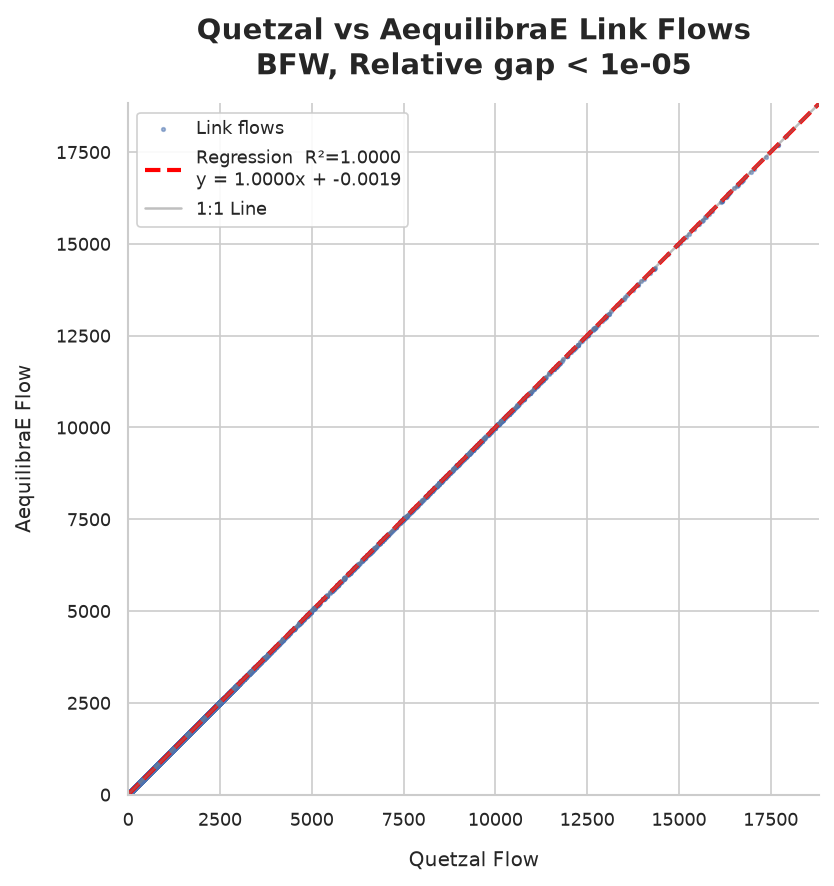

In [7]:
def plot_flow_comparison(quetzal_flows, aeq_flows, method, tolerance):
    sns.set_theme(style="whitegrid", context="paper")

    fig, ax = plt.subplots(figsize=(8, 6), dpi=150)

    ax.scatter(quetzal_flows, aeq_flows, alpha=0.5, s=3, label="Link flows")

    limit = max(*ax.get_xlim(), *ax.get_ylim())

    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    regression = linregress(quetzal_flows, aeq_flows)
    x_line = np.array([0, limit])
    y_line = regression.intercept + regression.slope * x_line
    ax.plot(
        x_line,
        y_line,
        linestyle="--",
        linewidth=2,
        label=f"Regression  R²={regression.rvalue**2:.4f}\ny = {regression.slope:.4f}x + {regression.intercept:.4f}",
        color="red",
    )

    ax.plot(
        [0, limit],
        [0, limit],
        linestyle="-",
        color="grey",
        alpha=0.5,
        label="1:1 Line",
    )

    ax.set_xlabel("Quetzal Flow", labelpad=10)
    ax.set_ylabel("AequilibraE Flow", labelpad=10)
    ax.set_title(
        f"Quetzal vs AequilibraE Link Flows\n{method.upper()}, Relative gap < {tolerance}",
        pad=14,
        fontweight="bold",
        fontsize=14,
    )

    ax.legend(frameon=True, framealpha=0.9, edgecolor="0.8", loc="upper left")
    sns.despine(left=False, bottom=False)

    ax.set_aspect("equal", adjustable="box")

    plt.tight_layout()
    plt.show()


quetzal_results = sm.road_links["flow"]
matched_flows = aeq_flows.loc[sm.road_links["link_id"], ["matrix_ab", "matrix_ba"]]
aeq_results = pd.Series(
    np.where(
        sm.road_links["link_direction"].eq(1),
        matched_flows["matrix_ab"],
        matched_flows["matrix_ba"],
    ),
    index=quetzal_results.index,
)
plot_flow_comparison(quetzal_results, aeq_results, method, tolerance)

In [8]:
(quetzal_results - aeq_results).describe()

count    35436.000000
mean         0.000016
std          0.210343
min         -4.412222
25%         -0.032678
50%          0.000000
75%          0.035883
max          4.638149
dtype: float64